#  Merge and Clean the Data

**Goal:** combine two files into one clean table that can predict **which product category a customer buys**.
(`customer_social_profiles.xlsx`, `customer_transactions.xlsx`) 

## 1. Load the data

In [23]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path


# Folder paths (this notebook lives in EDA/, so we go one level up)
RAW_DIR    = Path("../data/raw_data")
CLEAN_DIR  = Path("../data/cleaned_data")
MODELS_DIR = Path("../models")
CLEAN_DIR.mkdir(parents=True, exist_ok=True)
MODELS_DIR.mkdir(parents=True, exist_ok=True)

sns.set_theme(style="whitegrid")
pd.set_option("display.width", 150)
pd.set_option("display.max_columns", 30)

social = pd.read_excel(RAW_DIR / "customer_social_profiles.xlsx")
trans  = pd.read_excel(RAW_DIR / "customer_transactions.xlsx")

print("Social profiles :", social.shape)
print("Transactions    :", trans.shape)

Social profiles : (155, 5)
Transactions    : (150, 6)


In [24]:
social.head()

,customer_id_new,social_media_platform,engagement_score,purchase_interest_score,review_sentiment
0,A178,LinkedIn,74,4.9,Positive
1,A190,Twitter,82,4.8,Neutral
2,A150,Facebook,96,1.6,Positive
3,A162,Twitter,89,2.6,Positive
4,A197,Twitter,92,2.3,Neutral


In [25]:
trans.head()

,customer_id_legacy,transaction_id,purchase_amount,purchase_date,product_category,customer_rating
0,151,1001,408,2024-01-01,Sports,2.3
1,192,1002,332,2024-01-02,Electronics,4.2
2,114,1003,442,2024-01-03,Electronics,2.1
3,171,1004,256,2024-01-04,Clothing,2.8
4,160,1005,64,2024-01-05,Clothing,1.3


**First observations**
- The customer ID has a **different format** in each file: `A178` (social) vs `178` (transactions). We must make them match before joining.
- Both files are small (155 and 150 rows).

## 2. Check data quality (before cleaning)

In [26]:
print("=== SOCIAL ===")
print(social.dtypes, "\n")
print("Missing values:\n", social.isna().sum(), "\n")
print("Exact duplicate rows:", social.duplicated().sum())
print("Rows:", len(social), "| Unique customers:", social["customer_id_new"].nunique())

print("\n=== TRANSACTIONS ===")
print(trans.dtypes, "\n")
print("Missing values:\n", trans.isna().sum(), "\n")
print("Exact duplicate rows:", trans.duplicated().sum())
print("Duplicate transaction IDs:", trans["transaction_id"].duplicated().sum())
print("Rows:", len(trans), "| Unique customers:", trans["customer_id_legacy"].nunique())

=== SOCIAL ===
customer_id_new                str
social_media_platform          str
engagement_score             int64
purchase_interest_score    float64
review_sentiment               str
dtype: object 

Missing values:
 customer_id_new            0
social_media_platform      0
engagement_score           0
purchase_interest_score    0
review_sentiment           0
dtype: int64 

Exact duplicate rows: 5
Rows: 155 | Unique customers: 84

=== TRANSACTIONS ===
customer_id_legacy             int64
transaction_id                 int64
purchase_amount                int64
purchase_date         datetime64[us]
product_category                 str
customer_rating              float64
dtype: object 

Missing values:
 customer_id_legacy     0
transaction_id         0
purchase_amount        0
purchase_date          0
product_category       0
customer_rating       10
dtype: int64 

Exact duplicate rows: 0
Duplicate transaction IDs: 0
Rows: 150 | Unique customers: 75


**What we found**
- **Social:** 5 exact duplicate rows. Also, 155 rows belong to only 84 customers, so some customers appear **several times** (different platforms or scores).
- **Transactions:** no duplicates, but **10 missing ratings**. Each row is one purchase, and a customer can buy more than once.

## 3. Clean the social file

**3a. Make the customer ID a number** (remove the `A`) so it matches the transactions file.

In [27]:
social["customer_id"] = social["customer_id_new"].str.replace("A", "", regex=False).astype(int)
social = social.drop(columns="customer_id_new")
social["customer_id"].head()

0    178
1    190
2    150
3    162
4    197
Name: customer_id, dtype: int64

**3b. Remove exact duplicate rows** (same customer, same values = repeated by mistake).

In [28]:
before = len(social)
social = social.drop_duplicates()
print(f"Removed {before - len(social)} duplicate rows -> {len(social)} rows left")

Removed 5 duplicate rows -> 150 rows left


**3c. One row per customer.**
Some customers still appear more than once with *different* values. If we joined like this, one purchase would be copied several times and the data would be inflated.
So we **summarise each customer into one row**: average the scores, count sentiments, and keep their most-used platform.

In [29]:
# how many customers appear more than once?
rows_per_cust = social.groupby("customer_id").size()
print("Customers with more than 1 social row:", (rows_per_cust > 1).sum(), "of", len(rows_per_cust))

# turn sentiment into a number: Positive = +1, Neutral = 0, Negative = -1
social["sentiment_score"] = social["review_sentiment"].map({"Positive": 1, "Neutral": 0, "Negative": -1})

social_cust = social.groupby("customer_id").agg(
    avg_engagement        = ("engagement_score", "mean"),
    avg_purchase_interest = ("purchase_interest_score", "mean"),
    avg_sentiment         = ("sentiment_score", "mean"),
    n_social_profiles     = ("customer_id", "size"),
    main_platform         = ("social_media_platform", lambda x: x.value_counts().idxmax()),
).reset_index()

print("Social table is now one row per customer:", social_cust.shape)
social_cust.head()

Customers with more than 1 social row: 41 of 84
Social table is now one row per customer: (84, 6)


,customer_id,avg_engagement,avg_purchase_interest,avg_sentiment,n_social_profiles,main_platform
0,100,77.000000,4.400000,-0.500000,2,Twitter
1,101,68.000000,1.000000,0.000000,1,Twitter
2,102,51.000000,4.800000,0.000000,1,LinkedIn
3,103,64.333333,2.866667,0.333333,3,Instagram
4,104,83.000000,2.933333,-0.666667,3,Twitter


## 4. Clean the transactions file

**4a. Fix the missing ratings.**
10 of 150 ratings are empty. We fill them with the **overall median rating** (a typical value) and add a flag column `rating_was_missing` so the model can tell which were filled.
We use the overall median (not one per product) on purpose, because using the product would leak the answer we want to predict.

In [30]:
trans = trans.rename(columns={"customer_id_legacy": "customer_id"})

median_rating = trans["customer_rating"].median()
trans["rating_was_missing"] = trans["customer_rating"].isna().astype(int)
trans["customer_rating"] = trans["customer_rating"].fillna(median_rating)

print("Median rating used:", median_rating)
print("Missing ratings left:", trans["customer_rating"].isna().sum())

Median rating used: 3.0
Missing ratings left: 0


**4b. Check data types and outliers.**

In [31]:
print(trans.dtypes, "\n")

# Outlier check using the IQR rule
q1, q3 = trans["purchase_amount"].quantile([0.25, 0.75])
iqr = q3 - q1
low, high = q1 - 1.5 * iqr, q3 + 1.5 * iqr
outliers = trans[(trans["purchase_amount"] < low) | (trans["purchase_amount"] > high)]
print(f"Allowed purchase range: {low:.0f} to {high:.0f}  ->  outliers found: {len(outliers)}")
print("Rating range:", trans["customer_rating"].min(), "to", trans["customer_rating"].max())

customer_id                    int64
transaction_id                 int64
purchase_amount                int64
purchase_date         datetime64[us]
product_category                 str
customer_rating              float64
rating_was_missing             int64
dtype: object 

Allowed purchase range: -135 to 703  ->  outliers found: 0
Rating range: 1.0 to 5.0


Dates are already real dates, amounts are numbers, there are no outliers, and ratings stay between 1 and 5. The transactions file is clean.

## 5. Merge the two files

**Join choice: LEFT join, with transactions on the left, using `customer_id`.**

- Our target (the product bought) lives in the transactions file, so **every purchase must stay**. A left join keeps all 150.
- An *inner* join would throw away purchases from customers with no social profile.
- Customers with no social data get a flag (`has_social_data = 0`) and neutral filler values.
- Because we already made the social table **one row per customer**, the join cannot create extra rows.

In [32]:
merged = trans.merge(social_cust, on="customer_id", how="left")
merged["has_social_data"] = merged["avg_engagement"].notna().astype(int)
merged.head()

,customer_id,transaction_id,purchase_amount,purchase_date,product_category,customer_rating,rating_was_missing,avg_engagement,avg_purchase_interest,avg_sentiment,n_social_profiles,main_platform,has_social_data
0,151,1001,408,2024-01-01,Sports,2.3,0,71.666667,2.166667,-0.333333,3.0,Twitter,1
1,192,1002,332,2024-01-02,Electronics,4.2,0,60.000000,4.300000,1.000000,1.0,Instagram,1
2,114,1003,442,2024-01-03,Electronics,2.1,0,87.000000,4.800000,-1.000000,1.0,Facebook,1
3,171,1004,256,2024-01-04,Clothing,2.8,0,NaN,NaN,NaN,NaN,NaN,0
4,160,1005,64,2024-01-05,Clothing,1.3,0,72.666667,2.500000,0.333333,3.0,TikTok,1


### Merge checks

In [33]:
print("Transactions before merge :", len(trans))
print("Rows after merge          :", len(merged))
assert len(merged) == len(trans), "Merge changed the number of rows!"
assert not merged["transaction_id"].duplicated().any(), "Duplicate transactions after merge!"

matched = merged["has_social_data"].sum()
print(f"Purchases with social data: {matched} ({matched/len(merged):.0%})")
print(f"Purchases without         : {len(merged) - matched}")

cust_t = set(trans["customer_id"]); cust_s = set(social_cust["customer_id"])
print("\nCustomers in transactions :", len(cust_t))
print("Customers in social       :", len(cust_s))
print("Customers in both         :", len(cust_t & cust_s))
print("Only in transactions      :", len(cust_t - cust_s))
print("Only in social (unused)   :", len(cust_s - cust_t))

Transactions before merge : 150
Rows after merge          : 150
Purchases with social data: 117 (78%)
Purchases without         : 33

Customers in transactions : 75
Customers in social       : 84
Customers in both         : 61
Only in transactions      : 14
Only in social (unused)   : 23


**Result:** the row count stayed at **150**, with no duplicated purchases.
About **78% of purchases** have social data. The rest are marked with `has_social_data = 0`.
Some social-only customers never bought anything, so they are not used (nothing to predict for them).

**Fill the gaps** for purchases with no social data: use the typical (median) value, a neutral sentiment of 0, and `Unknown` as the platform.

In [34]:
for col in ["avg_engagement", "avg_purchase_interest"]:
    merged[col] = merged[col].fillna(merged[col].median())

merged["avg_sentiment"]     = merged["avg_sentiment"].fillna(0)
merged["n_social_profiles"] = merged["n_social_profiles"].fillna(0).astype(int)
merged["main_platform"]     = merged["main_platform"].fillna("Unknown")

print("Missing values left in merged data:", merged.isna().sum().sum())

Missing values left in merged data: 0


## 6. Create new features

New columns that give the model more to learn from:

| Feature | Plain meaning |
|---|---|
| `customer_total_spend`, `customer_avg_spend` | How much this customer spends overall / per purchase |
| `customer_n_purchases` | How often they buy |
| `customer_avg_rating` | How they usually rate |
| `amount_vs_customer_avg` | Was this purchase bigger or smaller than their usual? |
| `month`, `day_of_week`, `is_weekend` | When the purchase happened |
| `engagement_x_interest` | Engaged **and** interested at the same time |

We deliberately **do not** build features from past product categories, to avoid leaking the answer.

In [35]:
g = merged.groupby("customer_id")
merged["customer_n_purchases"]  = g["transaction_id"].transform("count")
merged["customer_total_spend"]  = g["purchase_amount"].transform("sum")
merged["customer_avg_spend"]    = g["purchase_amount"].transform("mean").round(2)
merged["customer_avg_rating"]   = g["customer_rating"].transform("mean").round(2)
merged["amount_vs_customer_avg"] = (merged["purchase_amount"] / merged["customer_avg_spend"]).round(3)

merged["month"]       = merged["purchase_date"].dt.month
merged["day_of_week"] = merged["purchase_date"].dt.dayofweek   # 0 = Monday
merged["is_weekend"]  = (merged["day_of_week"] >= 5).astype(int)

merged["engagement_x_interest"] = (merged["avg_engagement"] * merged["avg_purchase_interest"]).round(2)

merged.head()

/tmp/ipykernel_27496/3046745662.py:9: Pandas4Warning: Series.dt.dayofweek is deprecated and will be removed in a future version. Use Series.dt.day_of_week instead.
  merged["day_of_week"] = merged["purchase_date"].dt.dayofweek   # 0 = Monday


,customer_id,transaction_id,purchase_amount,purchase_date,product_category,customer_rating,rating_was_missing,avg_engagement,avg_purchase_interest,avg_sentiment,n_social_profiles,main_platform,has_social_data,customer_n_purchases,customer_total_spend,customer_avg_spend,customer_avg_rating,amount_vs_customer_avg,month,day_of_week,is_weekend,engagement_x_interest
0,151,1001,408,2024-01-01,Sports,2.3,0,71.666667,2.166667,-0.333333,3,Twitter,1,1,408,408.0,2.30,1.000,1,0,0,155.28
1,192,1002,332,2024-01-02,Electronics,4.2,0,60.000000,4.300000,1.000000,1,Instagram,1,2,823,411.5,4.05,0.807,1,1,0,258.00
2,114,1003,442,2024-01-03,Electronics,2.1,0,87.000000,4.800000,-1.000000,1,Facebook,1,4,1034,258.5,3.50,1.710,1,2,0,417.60
3,171,1004,256,2024-01-04,Clothing,2.8,0,77.000000,3.133333,0.000000,0,Unknown,0,3,543,181.0,2.27,1.414,1,3,0,241.27
4,160,1005,64,2024-01-05,Clothing,1.3,0,72.666667,2.500000,0.333333,3,TikTok,1,1,64,64.0,1.30,1.000,1,4,0,181.67


## 7. Explore the data (EDA)

### 7a. Summary statistics

In [36]:
merged.describe().T.round(2)

,count,mean,min,25%,50%,75%,max,std
customer_id,150.0,148.76,100.0,121.25,150.5,174.75,199.0,30.046425
transaction_id,150.0,1075.5,1001.0,1038.25,1075.5,1112.75,1150.0,43.445368
purchase_amount,150.0,280.78,51.0,179.0,274.0,388.5,495.0,121.329595
purchase_date,150,2024-03-15 12:00:00,2024-01-01 00:00:00,2024-02-07 06:00:00,2024-03-15 12:00:00,2024-04-21 18:00:00,2024-05-29 00:00:00,NaN
customer_rating,150.0,2.986,1.0,2.1,3.0,4.0,5.0,1.165789
rating_was_missing,150.0,0.066667,0.0,0.0,0.0,0.0,1.0,0.250279
avg_engagement,150.0,74.780556,50.0,68.3125,77.0,81.0,99.0,11.245823
avg_purchase_interest,150.0,3.089556,1.0,2.733333,3.133333,3.6,4.8,0.917616
avg_sentiment,150.0,0.081111,-1.0,-0.458333,0.0,0.625,1.0,0.662174
n_social_profiles,150.0,1.42,0.0,1.0,1.0,2.0,4.0,1.094648


In [37]:
print("Variable types:")
print(merged.dtypes.value_counts())
print("\nText columns:", merged.select_dtypes(include=["object", "string"]).columns.tolist())

Variable types:
int64             9
float64           8
str               2
int32             2
datetime64[us]    1
Name: count, dtype: int64

Text columns: ['product_category', 'main_platform']


Most columns are numbers. The only text columns are the **target** (`product_category`) and the **platform** (`main_platform`). Both will be converted to numbers before modelling.

### Plot 1 – How balanced is the target?

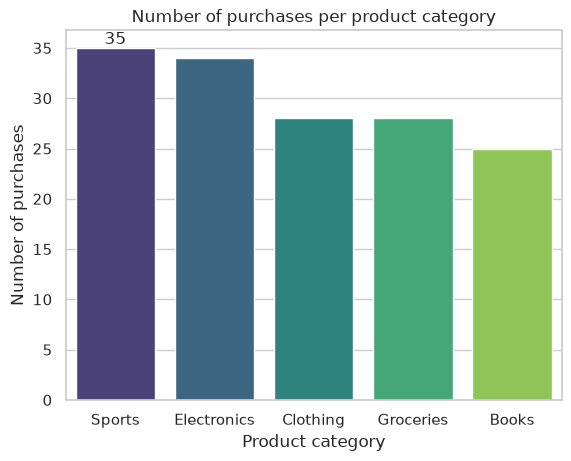

In [38]:
order = merged["product_category"].value_counts().index
ax = sns.countplot(data=merged, x="product_category", order=order, palette="viridis", hue="product_category", legend=False)
ax.bar_label(ax.containers[0])
plt.title("Number of purchases per product category")
plt.xlabel("Product category"); plt.ylabel("Number of purchases")
plt.show()

**What it shows:** the five categories are fairly even (from 25 to 35 purchases each). No category dominates, so a model cannot do well just by always guessing the most common one.
With only 150 rows, we should expect modest accuracy and use cross-validation later.

### Plot 2 – Purchase amount by product category (and outliers)

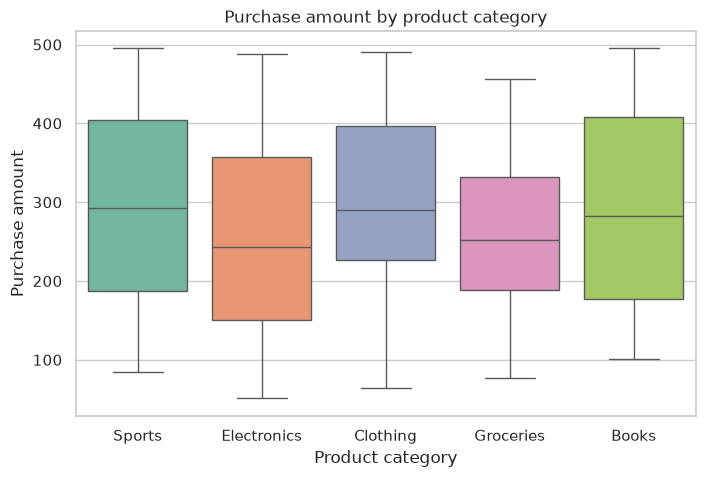

                   mean  median
product_category               
Books             306.0   282.0
Clothing          302.0   290.0
Electronics       253.0   243.0
Groceries         258.0   252.0
Sports            290.0   292.0


In [39]:
plt.figure(figsize=(8, 5))
sns.boxplot(data=merged, x="product_category", y="purchase_amount", order=order, palette="Set2", hue="product_category", legend=False)
plt.title("Purchase amount by product category")
plt.xlabel("Product category"); plt.ylabel("Purchase amount")
plt.show()

print(merged.groupby("product_category")["purchase_amount"].agg(["mean", "median"]).round(0))

**What it shows:** there are **no outliers** (no dots outside the boxes). Electronics and Groceries have slightly lower typical amounts than Books and Clothing.
But the boxes overlap a lot, so **amount alone cannot tell the categories apart**.

### Plot 3 – Distribution of the main numeric features

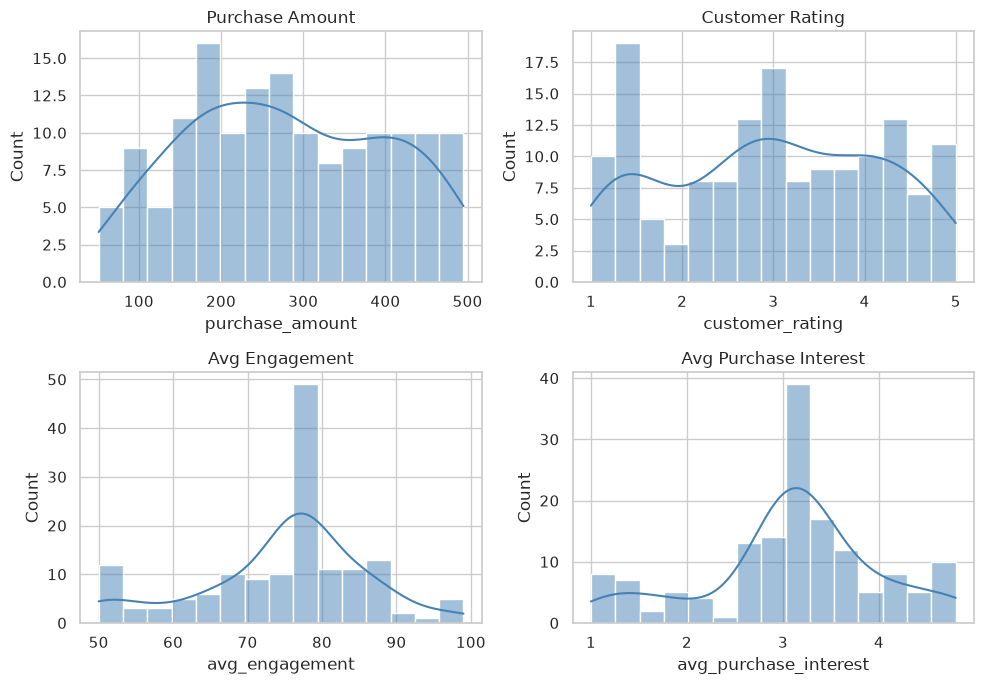

In [40]:
cols = ["purchase_amount", "customer_rating", "avg_engagement", "avg_purchase_interest"]
fig, axes = plt.subplots(2, 2, figsize=(10, 7))
for ax, c in zip(axes.ravel(), cols):
    sns.histplot(merged[c], bins=15, kde=True, ax=ax, color="steelblue")
    ax.set_title(c.replace("_", " ").title())
plt.tight_layout()
plt.show()

**What it shows:** `purchase_amount` and `customer_rating` are spread fairly evenly over their ranges (no big skew, no extreme values), so no transformation is needed.
`avg_engagement` and `avg_purchase_interest` show a few spikes. These come from the **filled-in median** for customers with no social data.

### Plot 4 – Do social signals differ by product?

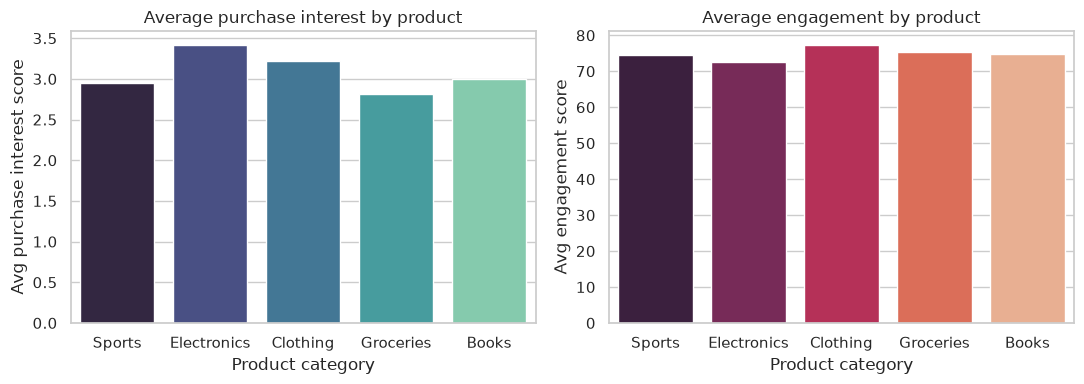

In [41]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
sns.barplot(data=merged, x="product_category", y="avg_purchase_interest", order=order, ax=axes[0],
            palette="mako", hue="product_category", legend=False, errorbar=None)
axes[0].set_title("Average purchase interest by product")
axes[0].set_xlabel("Product category"); axes[0].set_ylabel("Avg purchase interest score")

sns.barplot(data=merged, x="product_category", y="avg_engagement", order=order, ax=axes[1],
            palette="rocket", hue="product_category", legend=False, errorbar=None)
axes[1].set_title("Average engagement by product")
axes[1].set_xlabel("Product category"); axes[1].set_ylabel("Avg engagement score")
plt.tight_layout(); plt.show()

**What it shows:** engagement is very similar for every product. Purchase interest varies a bit more (Electronics buyers look slightly more interested than Groceries buyers).
These are small gaps, so the social data may help only a little. That is fine: we still keep it, since combining both files is the point of the task.

### Plot 5 – Correlations between numeric features

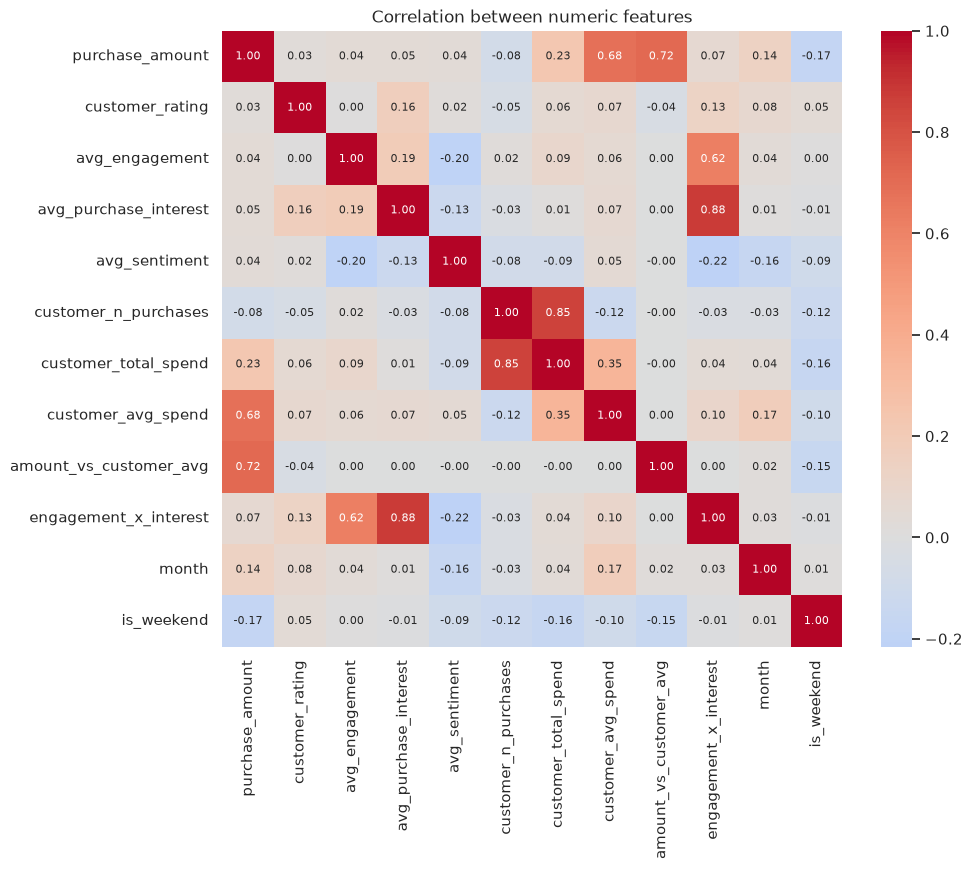

In [42]:
num_cols = ["purchase_amount", "customer_rating", "avg_engagement", "avg_purchase_interest", "avg_sentiment",
            "customer_n_purchases", "customer_total_spend", "customer_avg_spend", "amount_vs_customer_avg",
            "engagement_x_interest", "month", "is_weekend"]
plt.figure(figsize=(10, 8))
sns.heatmap(merged[num_cols].corr(), annot=True, fmt=".2f", cmap="coolwarm", center=0, annot_kws={"size": 8})
plt.title("Correlation between numeric features")
plt.show()

**What it shows:**
- The strong links are all between a feature and something we built from it: `customer_total_spend` with `customer_n_purchases` (0.85), `engagement_x_interest` with its parts (0.62 and 0.88), and `purchase_amount` with `customer_avg_spend` / `amount_vs_customer_avg` (0.68 and 0.72). That is expected.
- The original columns are almost unrelated to each other (e.g. amount vs. rating is about 0.03), so each adds its own information.
- **Next step for modelling:** when we train, we can drop one feature from each strongly linked pair to avoid repeating information.

## 8. Prepare and save the final dataset

The model needs numbers, so we turn the platform column into 0/1 columns (one-hot encoding). We keep the target `product_category` as readable text.

In [43]:
final = merged.drop(columns=["purchase_date"]).copy()   # date is already split into month / day_of_week

final_encoded = pd.get_dummies(final, columns=["main_platform"], prefix="platform", dtype=int)

print("Readable dataset :", final.shape)
print("Encoded dataset  :", final_encoded.shape)
final_encoded.head()

Readable dataset : (150, 21)
Encoded dataset  : (150, 26)


,customer_id,transaction_id,purchase_amount,product_category,customer_rating,rating_was_missing,avg_engagement,avg_purchase_interest,avg_sentiment,n_social_profiles,has_social_data,customer_n_purchases,customer_total_spend,customer_avg_spend,customer_avg_rating,amount_vs_customer_avg,month,day_of_week,is_weekend,engagement_x_interest,platform_Facebook,platform_Instagram,platform_LinkedIn,platform_TikTok,platform_Twitter,platform_Unknown
0,151,1001,408,Sports,2.3,0,71.666667,2.166667,-0.333333,3,1,1,408,408.0,2.30,1.000,1,0,0,155.28,0,0,0,0,1,0
1,192,1002,332,Electronics,4.2,0,60.000000,4.300000,1.000000,1,1,2,823,411.5,4.05,0.807,1,1,0,258.00,0,1,0,0,0,0
2,114,1003,442,Electronics,2.1,0,87.000000,4.800000,-1.000000,1,1,4,1034,258.5,3.50,1.710,1,2,0,417.60,1,0,0,0,0,0
3,171,1004,256,Clothing,2.8,0,77.000000,3.133333,0.000000,0,0,3,543,181.0,2.27,1.414,1,3,0,241.27,0,0,0,0,0,1
4,160,1005,64,Clothing,1.3,0,72.666667,2.500000,0.333333,3,1,1,64,64.0,1.30,1.000,1,4,0,181.67,0,0,0,1,0,0


In [44]:
merged.to_csv(CLEAN_DIR / "merged_dataset.csv", index=False)               # readable version (with dates and platform names)
final_encoded.to_csv(CLEAN_DIR / "merged_dataset_encoded.csv", index=False) # ready for model training

print("Saved both files in", CLEAN_DIR)

Saved both files in ../data/cleaned_data


## Summary

- **Cleaned** the social file (fixed ID, removed 5 duplicates, one row per customer) and the transactions file (filled 10 missing ratings, checked types and outliers).
- **Merged** with a left join on `customer_id`: **150 rows in, 150 rows out**, about 78% of purchases matched to social data, the rest flagged.
- **Added** spending, timing and social features, without leaking the target.
- **Explored** the data with 5 labelled plots. The target is balanced, there are no outliers, and the signals are weak.
- **Saved** `merged_dataset.csv` and `merged_dataset_encoded.csv` in `data/cleaned_data/`.

**Next:** `training_models/product_model_training.ipynb` trains the Product Recommendation Model.